# Análises da replicação — identificação do tipo de coluna (CTA)

Recalcula, a partir dos arquivos gravados em `data/column_type_annotation/enterprisetables_cta_pub/experiments/`, as análises das rodadas de 2026-11-15 e 2026-11-19. Não faz chamadas de API.

- Replicação (Tabela 12 de Bodensohn et al., arXiv:2504.10950, apêndice A.1): GPT-4o e GPT-4o-Mini, `temperature: 0`.
- Extensão: GPT-6.1 Terra, Claude Sonnet 5.5, Claude Haiku 5.5, sem `temperature: 0` e com raciocínio no padrão.
- As versões seguem os rótulos das pastas do conjunto publicado (C2 = esparsidade, C3 = descritividade).

Dados: as respostas dos modelos não ficam soltas no repositório. Antes de executar, descompacte na raiz: `unzip datasets/replicacao-cta-respostas.zip` (cria `data/column_type_annotation/...`).

## 0. Carregamento dos dados

Lê, de cada execução, o gabarito (`instances/`), a previsão (`predictions/`) e a resposta bruta (`responses/`). Nenhuma chamada de API é feita. Duas tabelas são montadas: `cols` (uma linha por coluna avaliada) e `tabs` (uma linha por tabela/resposta).

In [1]:
import json, pathlib, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.width", 250, "display.max_columns", 60, "display.max_rows", 200)
pd.options.display.float_format = "{:.3f}".format

ROOT = pathlib.Path(".").resolve()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
EXP = ROOT / "data/column_type_annotation/enterprisetables_cta_pub/experiments"
FULL, PILOT = "enterprise-data-enterprisetables-cta-pub", "piloto5"

VERS = ["c1-large-table-widths", "c2-high-sparsity", "c3-low-descriptiveness", "c4-complex-data-types", "all-challenges"]
VER_PT = dict(zip(VERS, ["C1 tabelas largas", "C2 alta esparsidade", "C3 nomes pouco descritivos", "C4 tipos complexos", "Todas as dificuldades"]))
HDRS = ["with-headers", "without-headers"]
HDR_PT = {"with-headers": "com nomes", "without-headers": "sem nomes"}
MODELS = ["gpt-6.1-terra", "claude-sonnet-5-5", "claude-haiku-5-5"]          # extensão: modelos atuais
REPL = ["gpt-4o-2024-08-06", "gpt-4o-mini-2024-07-18"]                        # replicação: modelos da Tabela 12 do artigo
REPS = ["repeticao2", "repeticao3"]                                          # execuções repetidas do GPT-4o-Mini
MODEL_PT = {"gpt-6.1-terra": "GPT-6.1 Terra", "claude-sonnet-5-5": "Claude Sonnet 5.5", "claude-haiku-5-5": "Claude Haiku 5.5",
            "gpt-4o-2024-08-06": "GPT-4o (2024-08-06)", "gpt-4o-mini-2024-07-18": "GPT-4o-Mini (2024-07-18)",
            "claude-fable-5-2": "Claude Fable 5.2"}
# mesmas cores dos gráficos já gerados (replicacao_graficos.py, paleta Okabe-Ito)
MODEL_COLOR = {"gpt-6.1-terra": "#E69F00", "claude-sonnet-5-5": "#56B4E9", "claude-haiku-5-5": "#D55E00",
               "gpt-4o-2024-08-06": "#0072B2", "gpt-4o-mini-2024-07-18": "#CC79A7"}

col_rows, tab_rows, LABELS = [], [], None
for d in sorted(EXP.glob("*_*_*_*")):
    prefix, model, ver, hdr = d.name.split("_")
    if not (d / "predictions").is_dir():
        continue
    labels = json.loads((d / "instances/all_column_types.json").read_text())
    assert LABELS is None or labels == LABELS      # a lista de tipos é a mesma em todas as execuções
    LABELS = labels
    label_set = set(labels)
    for inst in sorted(p for p in (d / "instances").iterdir() if p.is_dir()):
        t = int(inst.name)
        true = json.loads((inst / "column_types.json").read_text())
        dtypes = json.loads((inst / "data_types.json").read_text())
        pred = json.loads((d / "predictions" / inst.name / "column_types.json").read_text())
        err = json.loads((d / "predictions" / inst.name / "error.json").read_text())
        pred = [] if pred is None else pred
        resp = json.loads((d / "responses" / f"{inst.name}.json").read_text())
        if "choices" in resp:   # formato OpenAI (OpenRouter)
            u = resp["usage"]
            reasoning_tokens = (u.get("completion_tokens_details") or {}).get("reasoning_tokens") or 0
            think, out_tok, stop = reasoning_tokens > 0, u["completion_tokens"], resp["choices"][0]["finish_reason"]
            in_tok, cost = u["prompt_tokens"], u.get("cost")
        else:                   # formato Anthropic
            u = resp["usage"]
            think = any(b["type"] in ("thinking", "redacted_thinking") for b in resp["content"])
            out_tok, stop = u["output_tokens"], resp["stop_reason"]
            in_tok, cost = None, None
        tab_rows.append(dict(fase=prefix, model=model, ver=ver, hdr=hdr, t=t, n_cols=len(true),
                             n_anotadas=sum(x is not None for x in true), n_pred=len(pred), desvio=len(pred) - len(true),
                             erro_leitura=err, raciocinio=think, tokens_entrada=in_tok, tokens_saida=out_tok,
                             custo_informado=cost, stop=stop))
        # mesma regra do evaluate.py: a lista mais curta é completada com "MISSING"; colunas sem gabarito são ignoradas
        for i in range(max(len(true), len(pred))):
            tv = true[i] if i < len(true) else "MISSING"
            if tv is None:
                continue
            pv = pred[i] if i < len(pred) else "MISSING"
            col_rows.append((prefix, model, ver, hdr, t, i, tv, str(pv), dtypes[i] if i < len(dtypes) else None, pv in label_set))

cols = pd.DataFrame(col_rows, columns=["fase", "model", "ver", "hdr", "t", "i", "true", "pred", "dtype", "pred_valida"])
tabs = pd.DataFrame(tab_rows)
K = len(LABELS)
code_of = {l: i for i, l in enumerate(LABELS)}
cols["tc"] = cols["true"].map(code_of).fillna(K).astype(int)   # K = fora da lista de tipos
cols["pc"] = cols["pred"].map(code_of).fillna(K).astype(int)
cols["ok"] = cols["true"] == cols["pred"]
real = cols[cols["true"] != "MISSING"]      # colunas que existem no gabarito e têm tipo anotado

print("tipos na lista:", K)
print(tabs.groupby(["fase", "model"]).size().rename("respostas").to_string())
x = tabs[(tabs.fase == FULL) & (tabs.model == MODELS[0]) & (tabs.hdr == HDRS[0])]
print("\nColunas por versão (100 tabelas cada): total / com tipo anotado no gabarito (as únicas avaliadas)")
print(x.groupby("ver")[["n_cols", "n_anotadas"]].sum().loc[VERS].to_string())

tipos na lista: 452
fase                                      model                 
enterprise-data-enterprisetables-cta-pub  claude-haiku-5-5          1000
                                          claude-sonnet-5-5         1000
                                          gpt-4o-2024-08-06         1000
                                          gpt-4o-mini-2024-07-18    1000
                                          gpt-6.1-terra             1000
piloto5                                   claude-fable-5-2            50
                                          claude-haiku-5-5            50
                                          claude-sonnet-5-5           50
                                          gpt-4o-2024-08-06           50
                                          gpt-4o-mini-2024-07-18      50
                                          gpt-6.1-terra               50
repeticao2                                gpt-4o-mini-2024-07-18    1000
repeticao3                             

## 1. Verificação do F1 contra o `gather.py`

In [2]:
def weighted_f1(tc, pc):
    """F1 ponderado pelo suporte, restrito aos tipos da lista (igual a classification_report(labels=...)['weighted avg'])."""
    tc, pc = np.asarray(tc), np.asarray(pc)
    tp = np.bincount(tc[tc == pc], minlength=K + 1)[:K]
    nt = np.bincount(tc, minlength=K + 1)[:K]
    npred = np.bincount(pc, minlength=K + 1)[:K]
    f1 = np.where(nt + npred > 0, 2 * tp / np.maximum(nt + npred, 1), 0.0)
    return float((f1 * nt).sum() / nt.sum())

def run(model, ver, hdr, fase=FULL, df=None):
    df = cols if df is None else df
    return df[(df.fase == fase) & (df.model == model) & (df.ver == ver) & (df.hdr == hdr)]

csv = pd.read_csv(ROOT / "experiments/enterprise_data_enterprisetables_cta_pub/f1_scores_column_headers.csv", header=[0, 1, 2], index_col=0)
check = []
for m, v, h in itertools.product(MODELS + REPL, VERS, HDRS):
    g = run(m, v, h)
    official = csv.loc[[i for i in csv.index if i.endswith(m)][0], (v, "enterprisetables_cta_pub", h)]
    check.append(abs(weighted_f1(g.tc, g.pc) - official))
print(f"maior diferença absoluta entre o F1 recalculado aqui e o do gather.py, nas {len(check)} execuções: {max(check):.2e}")
assert max(check) < 1e-9

maior diferença absoluta entre o F1 recalculado aqui e o do gather.py, nas 50 execuções: 1.11e-16


## 2. Intervalo de confiança: bootstrap sobre as 100 tabelas (5.000 reamostras, pareado entre execuções)

In [3]:
B = 5000
rng = np.random.default_rng(20261119)
W = rng.multinomial(100, np.ones(100) / 100, size=B).astype(float)   # B reamostragens das 100 tabelas (as mesmas para todas as execuções)

def per_table_counts(g):
    tp, nt, npred = np.zeros((100, K + 1)), np.zeros((100, K + 1)), np.zeros((100, K + 1))
    np.add.at(nt, (g.t.values, g.tc.values), 1)
    np.add.at(npred, (g.t.values, g.pc.values), 1)
    hit = g[g.tc == g.pc]
    np.add.at(tp, (hit.t.values, hit.tc.values), 1)
    return tp[:, :K], nt[:, :K], npred[:, :K]

def boot_f1(g):
    with np.errstate(all="ignore"):   # o BLAS do macOS emite avisos espúrios em matmul; os valores são conferidos na célula seguinte
        tp, nt, npred = (W @ a for a in per_table_counts(g))
    f1 = np.where(nt + npred > 0, 2 * tp / np.maximum(nt + npred, 1e-12), 0.0)
    return (f1 * nt).sum(axis=1) / nt.sum(axis=1)

def ci(x):
    return np.percentile(x, [2.5, 97.5])

BOOT = {}

## 3. Replicação da Tabela 12: GPT-4o e GPT-4o-Mini

In [4]:
# Tabela 12 do relatório técnico estendido (arXiv:2504.10950v2, apêndice A.1), F1 ponderado: (sem nomes, com nomes).
# As versões são identificadas pelo nome da linha na tabela do artigo, não pelo número C1-C4.
PAPER = {
    "gpt-4o-mini-2024-07-18": {"c1-large-table-widths": (0.15, 0.31), "c2-high-sparsity": (0.07, 0.50), "c3-low-descriptiveness": (0.29, 0.25),
                               "c4-complex-data-types": (0.06, 0.50), "all-challenges": (0.02, 0.08)},
    "gpt-4o-2024-08-06":      {"c1-large-table-widths": (0.25, 0.60), "c2-high-sparsity": (0.21, 0.86), "c3-low-descriptiveness": (0.62, 0.74),
                               "c4-complex-data-types": (0.17, 0.90), "all-challenges": (0.04, 0.42)},
}
PAPER_ORIGINAL = {"gpt-4o-mini-2024-07-18": (0.27, 0.55), "gpt-4o-2024-08-06": (0.57, 0.91)}   # linha "SportsTables (Original)", não reproduzida aqui

T_all = tabs[tabs.fase == FULL]
rows = []
for m, v, h in itertools.product(REPL, VERS, HDRS):
    g = run(m, v, h); BOOT[m, v, h] = boot_f1(g); lo, hi = ci(BOOT[m, v, h])
    t = T_all[(T_all.model == m) & (T_all.ver == v) & (T_all.hdr == h)]
    p = PAPER[m][v][0 if h == "without-headers" else 1]
    rows.append(dict(model=m, ver=v, hdr=h, artigo=p, f1=weighted_f1(g.tc, g.pc), ic_inf=lo, ic_sup=hi,
                     cortadas=int((t.stop == "length").sum()), erros_leitura=int(t.erro_leitura.notna().sum()), custo=t.custo_informado.sum()))
repl = pd.DataFrame(rows)
repl["dif"] = repl.f1 - repl.artigo
# o artigo publica 2 casas decimais: o valor publicado é compatível se o intervalo [artigo ± 0,005] cruza o IC 95%
repl["artigo dentro do IC 95%"] = (repl.artigo + 0.005 >= repl.ic_inf) & (repl.artigo - 0.005 <= repl.ic_sup)
show = repl.assign(Modelo=repl.model.map(MODEL_PT), Versão=repl.ver.map(VER_PT), Condição=repl.hdr.map(HDR_PT),
                   **{"replicação [IC 95%]": repl.apply(lambda r: f"{r.f1:.3f} [{r.ic_inf:.3f}; {r.ic_sup:.3f}]", axis=1)})
show = show.rename(columns={"dif": "diferença", "cortadas": "respostas cortadas (de 100)", "erros_leitura": "erros de leitura"})
display(show.set_index(["Modelo", "Versão", "Condição"])[["artigo", "replicação [IC 95%]", "diferença", "artigo dentro do IC 95%", "respostas cortadas (de 100)", "erros de leitura"]])
print(f"células: {len(repl)} | maior diferença absoluta: {repl.dif.abs().max():.3f} | diferença absoluta mediana: {repl.dif.abs().median():.3f} | "
      f"diferença média (com sinal): {repl.dif.mean():+.3f} | replicação abaixo do artigo em {(repl.dif < 0).sum()} células | "
      f"valor do artigo dentro do IC em {repl['artigo dentro do IC 95%'].sum()}")
print(f"correlação de Pearson entre artigo e replicação nas {len(repl)} células: {np.corrcoef(repl.artigo, repl.f1)[0, 1]:.4f}")
print("custo informado pelo OpenRouter (US$):", repl.groupby("model").custo.sum().round(2).to_dict())

artigo   replicação [IC 95%]  diferença  artigo dentro do IC 95%  respostas cortadas (de 100)  erros de leitura
Modelo                   Versão                     Condição                                                                                                                  
GPT-4o (2024-08-06)      C1 tabelas largas          com nomes   0.600  0.581 [0.508; 0.691]     -0.019                     True                           28                 0
                                                    sem nomes   0.250  0.227 [0.200; 0.330]     -0.023                     True                           34                 0
                         C2 alta esparsidade        com nomes   0.860  0.878 [0.835; 0.916]      0.018                     True                            0                 0
                                                    sem nomes   0.210  0.197 [0.161; 0.235]     -0.013                     True                            1                 0
                         C3 nomes pouco descritivos com nomes   0.740  0.763 [0.713; 0.810]      0.023                     True                            0                 0
                                                    sem nomes   0.620  0.584 [0.531; 0.641]     -0.036                     True                            0                 0
                         C4 tipos complexos         com nomes   0.900  0.879 [0.831; 0.922]     -0.021                     True                            0                 0
                                                    sem nomes   0.170  0.165 [0.125; 0.209]     -0.005                     True                            1                 0
                         Todas as dificuldades      com nomes   0.420  0.382 [0.317; 0.441]     -0.038                     True                           24                 0
                                                    sem nomes   0.040  0.036 [0.026; 0.052]     -0.004                     True                           45                 0
GPT-4o-Mini (2024-07-18) C1 tabelas largas          com nomes   0.310  0.300 [0.235; 0.358]     -0.010                     True                           17                 0
                                                    sem nomes   0.150  0.129 [0.100; 0.172]     -0.021                     True                           21                 0
                         C2 alta esparsidade        com nomes   0.500  0.459 [0.390; 0.518]     -0.041                     True                            0                 0
                                                    sem nomes   0.070  0.068 [0.050; 0.087]     -0.002                     True                            0                 0
                         C3 nomes pouco descritivos com nomes   0.250  0.240 [0.208; 0.274]     -0.010                     True                            0                 0
                                                    sem nomes   0.290  0.291 [0.252; 0.332]      0.001                     True                            0                 0
                         C4 tipos complexos         com nomes   0.500  0.467 [0.398; 0.536]     -0.033                     True                            0                 0
                                                    sem nomes   0.060  0.048 [0.031; 0.067]     -0.012                     True                            0                 0
                         Todas as dificuldades      com nomes   0.080  0.075 [0.055; 0.095]     -0.005                     True                           25                 0
                                                    sem nomes   0.020  0.017 [0.010; 0.023]     -0.003                     True                           17                 0

células: 20 | maior diferença absoluta: 0.041 | diferença absoluta mediana: 0.016 | diferença média (com sinal): -0.013 | replicação abaixo do artigo em 17 células | valor do artigo dentro do IC em 20
correlação de Pearson entre artigo e replicação nas 20 células: 0.9981
custo informado pelo OpenRouter (US$): {'gpt-4o-2024-08-06': 31.04, 'gpt-4o-mini-2024-07-18': 1.32}


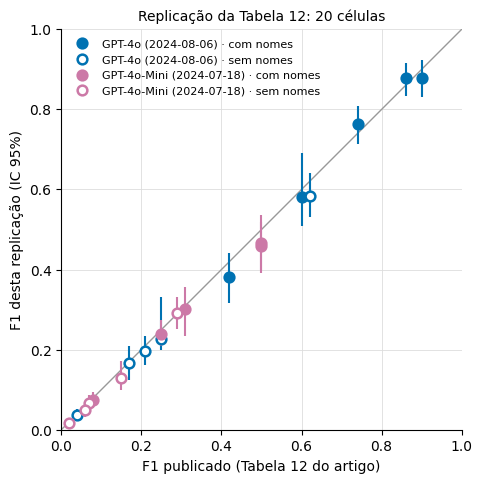

In [5]:
fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.plot([0, 1], [0, 1], color="#999999", lw=1, zorder=1)
for m in REPL:
    for h, face in [("with-headers", MODEL_COLOR[m]), ("without-headers", "white")]:
        r = repl[(repl.model == m) & (repl.hdr == h)]
        ax.errorbar(r.artigo, r.f1, yerr=[r.f1 - r.ic_inf, r.ic_sup - r.f1], fmt="none", ecolor=MODEL_COLOR[m], elinewidth=1.5, zorder=2)
        ax.plot(r.artigo, r.f1, "o", ms=7, mfc=face, mec=MODEL_COLOR[m], mew=1.8, zorder=3, label=f"{MODEL_PT[m]} · {HDR_PT[h]}")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
ax.set_xlabel("F1 publicado (Tabela 12 do artigo)"); ax.set_ylabel("F1 desta replicação (IC 95%)")
ax.grid(color="#dddddd", lw=0.6); ax.set_axisbelow(True)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.legend(loc="upper left", frameon=False, fontsize=8)
ax.set_title("Replicação da Tabela 12: 20 células", fontsize=10)
fig.savefig(ROOT / "graficos/analise_replicacao_tabela12.png", dpi=300, bbox_inches="tight"); fig.savefig(ROOT / "graficos/analise_replicacao_tabela12.pdf", bbox_inches="tight")
plt.show()

## 4. Variação entre 3 execuções do GPT-4o-Mini

In [6]:
MINI = "gpt-4o-mini-2024-07-18"
fases = [FULL] + [f for f in REPS if ((tabs.fase == f) & (tabs.model == MINI)).any()]
rows = []
for v, h in itertools.product(VERS, HDRS):
    row = {"Versão": VER_PT[v], "Condição": HDR_PT[h]}
    preds = []
    for k, f in enumerate(fases, start=1):
        g = run(MINI, v, h, fase=f)
        assert g.t.nunique() == 100, (f, v, h)
        row[f"execução {k}"] = weighted_f1(g.tc, g.pc)
        preds.append(g.groupby("t").pred.agg(tuple))
    vals = [row[f"execução {k}"] for k in range(1, len(fases) + 1)]
    row["desvio-padrão"] = float(np.std(vals, ddof=1)) if len(vals) > 1 else np.nan
    row["amplitude"] = max(vals) - min(vals)
    row["média"] = float(np.mean(vals)); row["artigo"] = PAPER[MINI][v][0 if h == "without-headers" else 1]
    row["média − artigo"] = row["média"] - row["artigo"]
    if len(preds) > 1:   # tabelas cuja lista de tipos previstos (colunas avaliadas) é idêntica em todas as execuções
        row["tabelas com previsão idêntica (de 100)"] = int(pd.concat(preds, axis=1).apply(lambda r: len(set(r)) == 1, axis=1).sum())
    rows.append(row)
var = pd.DataFrame(rows).set_index(["Versão", "Condição"])
pd.options.display.float_format = "{:.4f}".format
display(var)
pd.options.display.float_format = "{:.3f}".format
if len(fases) > 1:
    print(f"execuções: {len(fases)} | maior desvio-padrão: {var['desvio-padrão'].max():.4f} | mediano: {var['desvio-padrão'].median():.4f} | maior amplitude: {var['amplitude'].max():.4f}")
    largura = (repl[repl.model == MINI].ic_sup - repl[repl.model == MINI].ic_inf) / 2
    print(f"para comparação, meia-largura do IC 95% por amostragem de tabelas no mesmo modelo: mediana {largura.median():.3f}, máxima {largura.max():.3f}")
    print("referência do artigo (Tabela 11, conjuntos originais, 3 execuções): desvio-padrão entre 0,0003 e 0,0162")
    fora = (var["média − artigo"].abs() - 0.005 > var["amplitude"]).sum()
    print(f"média das execuções − artigo: de {var['média − artigo'].min():+.3f} a {var['média − artigo'].max():+.3f}, média {var['média − artigo'].mean():+.3f} | "
          f"células em que essa diferença (descontado o arredondamento do artigo) é maior que a amplitude entre as execuções: {fora} de {len(var)}")
    idt = var["tabelas com previsão idêntica (de 100)"]
    print(f"tabelas com previsão idêntica nas {len(fases)} execuções: de {idt.min()} a {idt.max()} em 100, conforme a configuração")

execução 1  execução 2  execução 3  desvio-padrão  amplitude  média  artigo  média − artigo  tabelas com previsão idêntica (de 100)
Versão                     Condição                                                                                                                                      
C1 tabelas largas          com nomes      0.3004      0.3212      0.3284         0.0146     0.0281 0.3167  0.3100          0.0067                                      26
                           sem nomes      0.1286      0.1257      0.1283         0.0016     0.0029 0.1275  0.1500         -0.0225                                       8
C2 alta esparsidade        com nomes      0.4588      0.4730      0.4736         0.0084     0.0148 0.4685  0.5000         -0.0315                                      33
                           sem nomes      0.0678      0.0686      0.0679         0.0005     0.0008 0.0681  0.0700         -0.0019                                      14
C3 nomes pouco descritivos com nomes      0.2395      0.2289      0.2316         0.0055     0.0107 0.2333  0.2500         -0.0167                                      11
                           sem nomes      0.2907      0.2708      0.2735         0.0108     0.0199 0.2783  0.2900         -0.0117                                      16
C4 tipos complexos         com nomes      0.4673      0.4741      0.4783         0.0055     0.0110 0.4732  0.5000         -0.0268                                      37
                           sem nomes      0.0483      0.0415      0.0440         0.0034     0.0068 0.0446  0.0600         -0.0154                                       6
Todas as dificuldades      com nomes      0.0751      0.0901      0.0748         0.0087     0.0152 0.0800  0.0800         -0.0000                                      16
                           sem nomes      0.0166      0.0175      0.0209         0.0023     0.0043 0.0183  0.0200         -0.0017                                      16

execuções: 3 | maior desvio-padrão: 0.0146 | mediano: 0.0055 | maior amplitude: 0.0281
para comparação, meia-largura do IC 95% por amostragem de tabelas no mesmo modelo: mediana 0.034, máxima 0.069
referência do artigo (Tabela 11, conjuntos originais, 3 execuções): desvio-padrão entre 0,0003 e 0,0162
média das execuções − artigo: de -0.032 a +0.007, média -0.012 | células em que essa diferença (descontado o arredondamento do artigo) é maior que a amplitude entre as execuções: 5 de 10
tabelas com previsão idêntica nas 3 execuções: de 6 a 37 em 100, conforme a configuração


## 5. Modelos atuais − GPT-4o (diferença pareada) e os cinco modelos

Diferença de F1 em relação ao GPT-4o desta replicação [IC 95% pareado]; (n.s.) = o intervalo inclui zero


Versão                                      C1 tabelas largas      C2 alta esparsidade C3 nomes pouco descritivos               C4 tipos complexos            Todas as dificuldades
Modelo                     Condição                                                                                                                                                
GPT-6.1 Terra − GPT-4o     com nomes  +0.382 [+0.273; +0.454]  +0.104 [+0.067; +0.148]    +0.223 [+0.177; +0.273]          +0.106 [+0.065; +0.154]          +0.430 [+0.366; +0.494]
                           sem nomes  +0.522 [+0.418; +0.548]  +0.687 [+0.633; +0.737]    +0.388 [+0.325; +0.447]          +0.475 [+0.410; +0.536]          +0.278 [+0.217; +0.322]
Claude Sonnet 5.5 − GPT-4o com nomes  +0.324 [+0.223; +0.385]  +0.099 [+0.062; +0.143]    +0.204 [+0.158; +0.254]          +0.080 [+0.036; +0.130]          +0.186 [+0.114; +0.245]
                           sem nomes  +0.444 [+0.338; +0.473]  +0.574 [+0.504; +0.639]    +0.382 [+0.325; +0.438]          +0.274 [+0.210; +0.333]          +0.149 [+0.108; +0.181]
Claude Haiku 5.5 − GPT-4o  com nomes  +0.232 [+0.135; +0.288]  -0.075 [-0.148; -0.004]    +0.082 [+0.032; +0.131]  +0.045 [-0.017; +0.102]  (n.s.)  +0.031 [-0.020; +0.087]  (n.s.)
                           sem nomes  +0.249 [+0.147; +0.278]  +0.204 [+0.157; +0.254]    +0.181 [+0.122; +0.237]          +0.049 [+0.009; +0.088]          +0.065 [+0.038; +0.089]

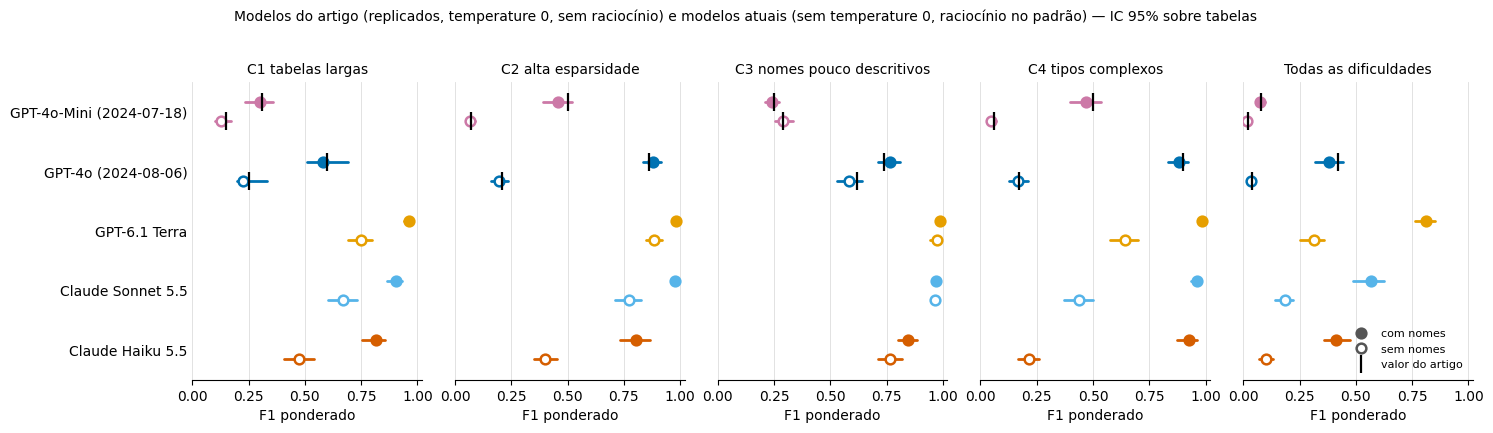

In [7]:
OBS = {(m, v, h): weighted_f1(run(m, v, h).tc, run(m, v, h).pc) for m, v, h in itertools.product(MODELS + REPL, VERS, HDRS)}
for m, v, h in itertools.product(MODELS, VERS, HDRS):
    if (m, v, h) not in BOOT:
        BOOT[m, v, h] = boot_f1(run(m, v, h))
rows = []
for m, v, h in itertools.product(MODELS, VERS, HDRS):
    d = BOOT[m, v, h] - BOOT["gpt-4o-2024-08-06", v, h]; lo, hi = ci(d)
    rows.append(dict(Modelo=MODEL_PT[m] + " − GPT-4o", Condição=HDR_PT[h], Versão=VER_PT[v],
                     celula=f"{OBS[m, v, h] - OBS['gpt-4o-2024-08-06', v, h]:+.3f} [{lo:+.3f}; {hi:+.3f}]" + ("" if (lo > 0 or hi < 0) else "  (n.s.)")))
print("Diferença de F1 em relação ao GPT-4o desta replicação [IC 95% pareado]; (n.s.) = o intervalo inclui zero")
display(pd.DataFrame(rows).pivot(index=["Modelo", "Condição"], columns="Versão", values="celula")[[VER_PT[v] for v in VERS]]
        .reindex([MODEL_PT[m] + " − GPT-4o" for m in MODELS], level=0))

ALL5 = REPL[::-1] + MODELS
fig, axes = plt.subplots(1, 5, figsize=(15, 4.2), sharey=True)
for ax, v in zip(axes, VERS):
    for j, m in enumerate(ALL5):
        for h, dy, face in [("with-headers", 0.16, MODEL_COLOR[m]), ("without-headers", -0.16, "white")]:
            lo, hi = ci(BOOT[m, v, h]); y = len(ALL5) - 1 - j + dy
            ax.plot([lo, hi], [y, y], color=MODEL_COLOR[m], lw=2, solid_capstyle="round", zorder=2)
            ax.plot(OBS[m, v, h], y, "o", ms=7, mfc=face, mec=MODEL_COLOR[m], mew=1.8, zorder=3)
            if m in PAPER:   # valor publicado no artigo
                ax.plot(PAPER[m][v][0 if h == "without-headers" else 1], y, marker="|", ms=13, mew=1.6, color="black", zorder=4)
    ax.set_title(VER_PT[v], fontsize=10); ax.set_xlim(0, 1.02); ax.set_ylim(-0.5, len(ALL5) - 0.5)
    ax.grid(axis="x", color="#dddddd", lw=0.6); ax.set_axisbelow(True)
    for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
    ax.tick_params(axis="y", length=0); ax.set_xlabel("F1 ponderado")
axes[0].set_yticks(range(len(ALL5))); axes[0].set_yticklabels([MODEL_PT[m] for m in reversed(ALL5)])
axes[-1].plot([], [], "o", ms=7, mfc="#555555", mec="#555555", mew=1.8, label="com nomes")
axes[-1].plot([], [], "o", ms=7, mfc="white", mec="#555555", mew=1.8, label="sem nomes")
axes[-1].plot([], [], marker="|", ms=13, mew=1.6, color="black", ls="none", label="valor do artigo")
axes[-1].legend(loc="lower right", frameon=False, fontsize=8)
fig.suptitle("Modelos do artigo (replicados, temperature 0, sem raciocínio) e modelos atuais (sem temperature 0, raciocínio no padrão) — IC 95% sobre tabelas", fontsize=10, y=1.02)
fig.tight_layout()
fig.savefig(ROOT / "graficos/analise_cinco_modelos.png", dpi=300, bbox_inches="tight"); fig.savefig(ROOT / "graficos/analise_cinco_modelos.pdf", bbox_inches="tight")
plt.show()

## 6. Modelos atuais: F1 ponderado com IC 95%

In [8]:
main_rows = []
for m, v, h in itertools.product(MODELS, VERS, HDRS):
    g = run(m, v, h)
    BOOT[m, v, h] = boot_f1(g)
    lo, hi = ci(BOOT[m, v, h])
    r = g[g["true"] != "MISSING"]
    main_rows.append(dict(model=m, ver=v, hdr=h, f1=weighted_f1(g.tc, g.pc), ic_inf=lo, ic_sup=hi, acuracia=r.ok.mean(), colunas=len(r)))
main = pd.DataFrame(main_rows)

fmt = lambda r: f"{r.f1:.3f} [{r.ic_inf:.3f}; {r.ic_sup:.3f}]"
t1 = main.assign(celula=main.apply(fmt, axis=1), Modelo=main.model.map(MODEL_PT), Condição=main.hdr.map(HDR_PT), Versão=main.ver.map(VER_PT))
t1 = t1.pivot(index=["Modelo", "Condição"], columns="Versão", values="celula")[[VER_PT[v] for v in VERS]].reindex([MODEL_PT[m] for m in MODELS], level=0)
assert all(np.isfinite(b).all() for b in BOOT.values()) and ((main.ic_inf <= main.f1) & (main.f1 <= main.ic_sup)).all()
print("F1 ponderado [IC 95% por bootstrap sobre as 100 tabelas]")
display(t1)

F1 ponderado [IC 95% por bootstrap sobre as 100 tabelas]


Versão                          C1 tabelas largas   C2 alta esparsidade C3 nomes pouco descritivos    C4 tipos complexos Todas as dificuldades
Modelo            Condição                                                                                                                    
GPT-6.1 Terra     com nomes  0.963 [0.942; 0.978]  0.983 [0.978; 0.988]       0.986 [0.980; 0.992]  0.985 [0.977; 0.992]  0.812 [0.764; 0.851]
                  sem nomes  0.749 [0.692; 0.799]  0.884 [0.848; 0.917]       0.972 [0.944; 0.989]  0.640 [0.574; 0.699]  0.313 [0.252; 0.361]
Claude Sonnet 5.5 com nomes  0.905 [0.865; 0.933]  0.978 [0.968; 0.986]       0.967 [0.956; 0.978]  0.960 [0.936; 0.979]  0.569 [0.487; 0.623]
                  sem nomes  0.670 [0.605; 0.733]  0.771 [0.710; 0.824]       0.966 [0.955; 0.977]  0.439 [0.372; 0.500]  0.185 [0.143; 0.220]
Claude Haiku 5.5  com nomes  0.814 [0.754; 0.858]  0.803 [0.731; 0.867]       0.845 [0.799; 0.884]  0.924 [0.874; 0.962]  0.413 [0.357; 0.474]
                  sem nomes  0.476 [0.408; 0.539]  0.402 [0.351; 0.454]       0.765 [0.711; 0.818]  0.214 [0.169; 0.259]  0.101 [0.072; 0.131]

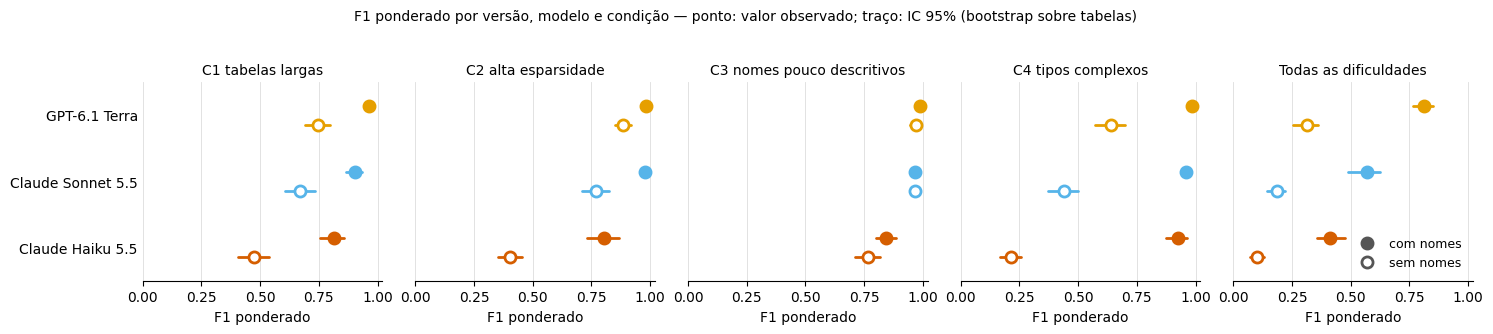

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2), sharey=True)
for ax, v in zip(axes, VERS):
    for j, m in enumerate(MODELS):
        for h, dy, face in [("with-headers", 0.14, MODEL_COLOR[m]), ("without-headers", -0.14, "white")]:
            r = main[(main.model == m) & (main.ver == v) & (main.hdr == h)].iloc[0]
            y = len(MODELS) - 1 - j + dy
            ax.plot([r.ic_inf, r.ic_sup], [y, y], color=MODEL_COLOR[m], lw=2, solid_capstyle="round", zorder=2)
            ax.plot(r.f1, y, "o", ms=8, mfc=face, mec=MODEL_COLOR[m], mew=2, zorder=3)
    ax.set_title(VER_PT[v], fontsize=10)
    ax.set_xlim(0, 1.02); ax.set_ylim(-0.5, len(MODELS) - 0.5)
    ax.grid(axis="x", color="#dddddd", lw=0.6); ax.set_axisbelow(True)
    for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
    ax.tick_params(axis="y", length=0); ax.set_xlabel("F1 ponderado")
axes[0].set_yticks(range(len(MODELS))); axes[0].set_yticklabels([MODEL_PT[m] for m in reversed(MODELS)])
axes[-1].plot([], [], "o", ms=8, mfc="#555555", mec="#555555", mew=2, label="com nomes")
axes[-1].plot([], [], "o", ms=8, mfc="white", mec="#555555", mew=2, label="sem nomes")
axes[-1].legend(loc="lower right", frameon=False, fontsize=9)
fig.suptitle("F1 ponderado por versão, modelo e condição — ponto: valor observado; traço: IC 95% (bootstrap sobre tabelas)", fontsize=10, y=1.03)
fig.tight_layout()
(ROOT / "graficos").mkdir(exist_ok=True)
fig.savefig(ROOT / "graficos/analise_f1_ic95.png", dpi=300, bbox_inches="tight"); fig.savefig(ROOT / "graficos/analise_f1_ic95.pdf", bbox_inches="tight")
plt.show()

## 7. Modelos atuais: queda de F1 ao remover os nomes

In [10]:
rows = []
for m, v in itertools.product(MODELS, VERS):
    d = BOOT[m, v, "with-headers"] - BOOT[m, v, "without-headers"]      # pareado: mesmas tabelas reamostradas nas duas condições
    obs = main.set_index(["model", "ver", "hdr"]).f1
    lo, hi = ci(d)
    rows.append(dict(Modelo=MODEL_PT[m], Versão=VER_PT[v], queda=obs[m, v, "with-headers"] - obs[m, v, "without-headers"], ic_inf=lo, ic_sup=hi))
drop = pd.DataFrame(rows)
drop["IC exclui 0"] = (drop.ic_inf > 0) | (drop.ic_sup < 0)
t2 = drop.assign(celula=drop.apply(lambda r: f"{r.queda:+.3f} [{r.ic_inf:+.3f}; {r.ic_sup:+.3f}]" + ("" if r["IC exclui 0"] else "  (n.s.)"), axis=1))
print("Queda de F1 ao remover os nomes (com nomes − sem nomes) [IC 95% pareado]; (n.s.) = o intervalo inclui zero")
display(t2.pivot(index="Modelo", columns="Versão", values="celula")[[VER_PT[v] for v in VERS]].reindex([MODEL_PT[m] for m in MODELS]))

Queda de F1 ao remover os nomes (com nomes − sem nomes) [IC 95% pareado]; (n.s.) = o intervalo inclui zero


Versão,C1 tabelas largas,C2 alta esparsidade,C3 nomes pouco descritivos,C4 tipos complexos,Todas as dificuldades
Modelo,,,,,
GPT-6.1 Terra,+0.214 [+0.163; +0.268],+0.098 [+0.065; +0.135],+0.014 [-0.003; +0.043] (n.s.),+0.345 [+0.286; +0.411],+0.499 [+0.448; +0.558]
Claude Sonnet 5.5,+0.235 [+0.178; +0.288],+0.206 [+0.153; +0.269],+0.001 [-0.012; +0.014] (n.s.),+0.521 [+0.458; +0.588],+0.384 [+0.307; +0.445]
Claude Haiku 5.5,+0.338 [+0.272; +0.399],+0.402 [+0.304; +0.491],+0.080 [+0.010; +0.148],+0.710 [+0.646; +0.768],+0.312 [+0.263; +0.366]


## 8. Modelos atuais: diferenças entre pares de modelos

In [11]:
rows = []
for (a, b), v, h in itertools.product(itertools.combinations(MODELS, 2), VERS, HDRS):
    d = BOOT[a, v, h] - BOOT[b, v, h]
    obs = main.set_index(["model", "ver", "hdr"]).f1
    lo, hi = ci(d)
    rows.append(dict(Par=f"{MODEL_PT[a]} − {MODEL_PT[b]}", Condição=HDR_PT[h], Versão=VER_PT[v], dif=obs[a, v, h] - obs[b, v, h], lo=lo, hi=hi))
pairs = pd.DataFrame(rows)
pairs["celula"] = pairs.apply(lambda r: f"{r.dif:+.3f} [{r.lo:+.3f}; {r.hi:+.3f}]" + ("" if (r.lo > 0 or r.hi < 0) else "  (n.s.)"), axis=1)
print("Diferença de F1 entre modelos [IC 95% pareado]; (n.s.) = o intervalo inclui zero")
display(pairs.pivot(index=["Par", "Condição"], columns="Versão", values="celula")[[VER_PT[v] for v in VERS]])

Diferença de F1 entre modelos [IC 95% pareado]; (n.s.) = o intervalo inclui zero


Versão                                                C1 tabelas largas              C2 alta esparsidade       C3 nomes pouco descritivos               C4 tipos complexos    Todas as dificuldades
Par                                  Condição                                                                                                                                                      
Claude Sonnet 5.5 − Claude Haiku 5.5 com nomes  +0.091 [+0.059; +0.130]          +0.174 [+0.112; +0.247]          +0.123 [+0.082; +0.169]  +0.036 [-0.008; +0.089]  (n.s.)  +0.155 [+0.074; +0.215]
                                     sem nomes  +0.195 [+0.155; +0.241]          +0.370 [+0.302; +0.435]          +0.201 [+0.147; +0.257]          +0.225 [+0.168; +0.279]  +0.084 [+0.047; +0.117]
GPT-6.1 Terra − Claude Haiku 5.5     com nomes  +0.149 [+0.110; +0.202]          +0.180 [+0.116; +0.252]          +0.141 [+0.102; +0.187]          +0.061 [+0.024; +0.111]  +0.399 [+0.337; +0.455]
                                     sem nomes  +0.273 [+0.231; +0.318]          +0.483 [+0.423; +0.541]          +0.207 [+0.151; +0.263]          +0.426 [+0.357; +0.491]  +0.212 [+0.159; +0.259]
GPT-6.1 Terra − Claude Sonnet 5.5    com nomes  +0.058 [+0.033; +0.092]  +0.005 [-0.000; +0.013]  (n.s.)          +0.019 [+0.008; +0.031]          +0.026 [+0.006; +0.049]  +0.244 [+0.196; +0.316]
                                     sem nomes  +0.078 [+0.050; +0.105]          +0.113 [+0.063; +0.174]  +0.005 [-0.023; +0.027]  (n.s.)          +0.201 [+0.135; +0.269]  +0.128 [+0.074; +0.181]

## 9. Modelos atuais: destino das colunas avaliadas

In [12]:
def categoria(df):
    return np.select(
        [df.ok, df.pred == "unspecified", df.pred == "MISSING", ~df.pred_valida],
        ["correta", '"unspecified" (abstenção)', "sem previsão (lista curta)", "outro rótulo fora da lista"],
        default="tipo válido, mas errado")
CATS = ["correta", "tipo válido, mas errado", '"unspecified" (abstenção)', "outro rótulo fora da lista", "sem previsão (lista curta)"]
r = real[real.fase == FULL].copy()
r["cat"] = categoria(r)
decomp = (r.groupby(["model", "ver", "hdr"]).cat.value_counts(normalize=True).unstack(fill_value=0)[CATS]
          .reindex(pd.MultiIndex.from_product([MODELS, VERS, HDRS])))
show = decomp.copy(); show.index = pd.MultiIndex.from_tuples([(MODEL_PT[m], VER_PT[v], HDR_PT[h]) for m, v, h in decomp.index], names=["Modelo", "Versão", "Condição"])
print("Destino de cada coluna avaliada (proporção das colunas com tipo anotado)")
display((show * 100).round(1))

Destino de cada coluna avaliada (proporção das colunas com tipo anotado)


cat                                                     correta  tipo válido, mas errado  "unspecified" (abstenção)  outro rótulo fora da lista  sem previsão (lista curta)
Modelo            Versão                     Condição                                                                                                                      
GPT-6.1 Terra     C1 tabelas largas          com nomes   95.600                    4.100                      0.000                       0.300                       0.000
                                             sem nomes   72.800                   26.100                      0.000                       0.000                       1.100
                  C2 alta esparsidade        com nomes   98.500                    1.500                      0.000                       0.000                       0.000
                                             sem nomes   88.200                   11.300                      0.000                       0.000                       0.500
                  C3 nomes pouco descritivos com nomes   98.600                    1.300                      0.000                       0.000                       0.000
                                             sem nomes   97.200                    2.800                      0.000                       0.000                       0.000
                  C4 tipos complexos         com nomes   98.500                    1.500                      0.000                       0.000                       0.000
                                             sem nomes   63.300                   36.300                      0.000                       0.000                       0.400
                  Todas as dificuldades      com nomes   80.300                   19.100                      0.500                       0.000                       0.100
                                             sem nomes   26.600                   69.100                      1.700                       1.400                       1.100
Claude Sonnet 5.5 C1 tabelas largas          com nomes   88.500                    5.700                      5.700                       0.000                       0.000
                                             sem nomes   65.500                   31.000                      3.100                       0.100                       0.300
                  C2 alta esparsidade        com nomes   97.900                    2.100                      0.000                       0.000                       0.000
                                             sem nomes   77.200                   22.100                      0.400                       0.000                       0.200
                  C3 nomes pouco descritivos com nomes   96.500                    3.100                      0.000                       0.400                       0.000
                                             sem nomes   96.500                    3.200                      0.000                       0.300                       0.000
                  C4 tipos complexos         com nomes   95.600                    4.200                      0.000                       0.100                       0.200
                                             sem nomes   42.800                   56.900                      0.000                       0.100                       0.200
                  Todas as dificuldades      com nomes   49.700                   20.300                     28.300                       0.100                       1.700
                                             sem nomes   15.800                   64.500                     19.200                       0.000                       0.400
Claude Haiku 5.5  C1 tabelas largas          com nomes   77.900                   10.500                      8.200                       0.900                       2.500
                                            

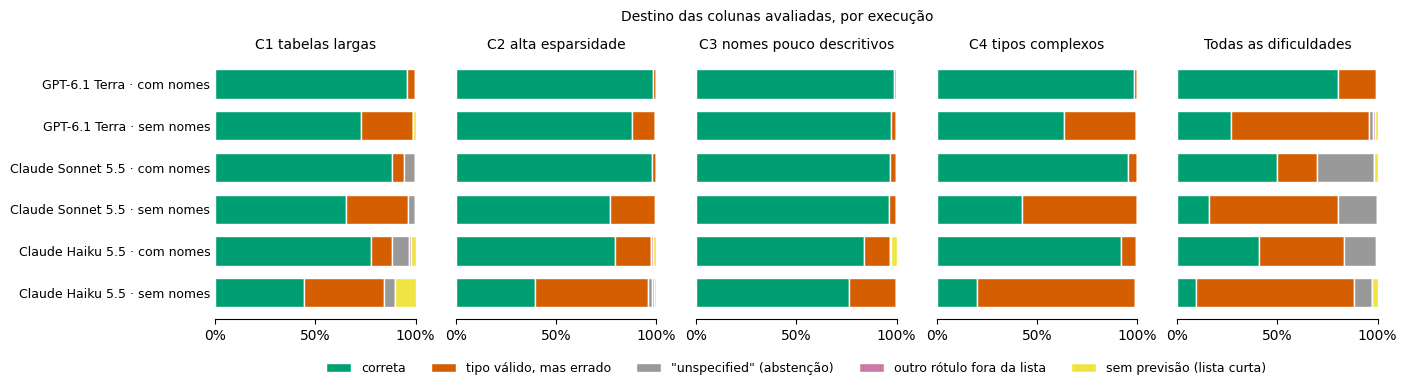

In [13]:
CAT_COLOR = dict(zip(CATS, ["#009E73", "#D55E00", "#999999", "#CC79A7", "#F0E442"]))
fig, axes = plt.subplots(1, 5, figsize=(15, 3.4), sharey=True)
ylab = [f"{MODEL_PT[m]} · {HDR_PT[h]}" for m in MODELS for h in HDRS]
for ax, v in zip(axes, VERS):
    left = np.zeros(6)
    for c in CATS:
        vals = np.array([decomp.loc[(m, v, h), c] for m in MODELS for h in HDRS])
        ax.barh(range(6), vals, left=left, color=CAT_COLOR[c], edgecolor="white", linewidth=1, height=0.7, label=c)
        left += vals
    ax.set_title(VER_PT[v], fontsize=10); ax.set_xlim(0, 1); ax.invert_yaxis()
    ax.set_xticks([0, 0.5, 1]); ax.set_xticklabels(["0%", "50%", "100%"])
    for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
    ax.tick_params(axis="y", length=0)
axes[0].set_yticks(range(6)); axes[0].set_yticklabels(ylab, fontsize=9)
axes[2].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=5, frameon=False, fontsize=9)
fig.suptitle("Destino das colunas avaliadas, por execução", fontsize=10, y=1.02)
fig.savefig(ROOT / "graficos/analise_destino_colunas.png", dpi=300, bbox_inches="tight"); fig.savefig(ROOT / "graficos/analise_destino_colunas.pdf", bbox_inches="tight")
plt.show()

## 10. Modelos atuais: número de colunas da resposta e influência de tabelas isoladas

In [14]:
T_full = tabs[tabs.fase == FULL]
rows = []
for m, v, h in itertools.product(MODELS, VERS, HDRS):
    g = run(m, v, h); t = T_full[(T_full.model == m) & (T_full.ver == v) & (T_full.hdr == h)]
    exact = set(t[t.desvio == 0].t); g0 = g[g.t.isin(exact)]
    loo = [weighted_f1(g[g.t != k].tc, g[g.t != k].pc) for k in range(100)]
    rows.append({"Modelo": MODEL_PT[m], "Versão": VER_PT[v], "Condição": HDR_PT[h],
                 "tabelas com nº de colunas correto": len(exact), "maior desvio (colunas)": int(t.desvio.abs().max()),
                 "F1 (todas)": weighted_f1(g.tc, g.pc), "F1 (só nº correto)": weighted_f1(g0.tc, g0.pc),
                 "F1 mín. sem 1 tabela": min(loo), "F1 máx. sem 1 tabela": max(loo)})
rob = pd.DataFrame(rows)
rob["ganho ao restringir"] = rob["F1 (só nº correto)"] - rob["F1 (todas)"]
display(rob.set_index(["Modelo", "Versão", "Condição"]))
x = real[real.fase == FULL].merge(T_full[["model", "ver", "hdr", "t", "desvio"]], on=["model", "ver", "hdr", "t"])
x["desvio no nº de colunas"] = np.select([x.desvio == 0, x.desvio.abs() <= 2], ["0", "1 a 2"], default="3 ou mais")
print("Acurácia das colunas segundo o desvio no número de colunas da resposta (todas as versões e condições)")
display(x.assign(Modelo=x.model.map(MODEL_PT)).groupby(["Modelo", "desvio no nº de colunas"]).ok.agg(acurácia="mean", colunas="size"))
print("Respostas que não terminaram normalmente / erros de leitura:")
display(T_full[(~T_full.stop.isin(["stop", "end_turn"])) | T_full.erro_leitura.notna()][["model", "ver", "hdr", "t", "n_cols", "n_pred", "stop", "erro_leitura"]])

tabelas com nº de colunas correto  maior desvio (colunas)  F1 (todas)  F1 (só nº correto)  F1 mín. sem 1 tabela  F1 máx. sem 1 tabela  ganho ao restringir
Modelo            Versão                     Condição                                                                                                                                                             
GPT-6.1 Terra     C1 tabelas largas          com nomes                                 95                       5       0.963               0.976                 0.962                 0.968                0.013
                                             sem nomes                                 92                     245       0.749               0.787                 0.743                 0.755                0.038
                  C2 alta esparsidade        com nomes                                100                       0       0.983               0.983                 0.983                 0.984                0.000
                                             sem nomes                                 90                       1       0.884               0.915                 0.883                 0.892                0.031
                  C3 nomes pouco descritivos com nomes                                100                       0       0.986               0.986                 0.986                 0.987                0.000
                                             sem nomes                                 99                       1       0.972               0.983                 0.971                 0.983                0.012
                  C4 tipos complexos         com nomes                                100                       0       0.985               0.985                 0.985                 0.989                0.000
                                             sem nomes                                 92                       2       0.640               0.655                 0.634                 0.653                0.015
                  Todas as dificuldades      com nomes                                 96                       2       0.812               0.830                 0.808                 0.819                0.017
                                             sem nomes                                 83                     171       0.313               0.346                 0.303                 0.318                0.033
Claude Sonnet 5.5 C1 tabelas largas          com nomes                                 87                      27       0.905               0.937                 0.903                 0.910                0.032
                                             sem nomes                                 73                      50       0.670               0.782                 0.664                 0.677                0.112
                  C2 alta esparsidade        com nomes                                 99                       1       0.978               0.980                 0.977                 0.980                0.003
                                             sem nomes                                 95                       1       0.771               0.785                 0.766                 0.783                0.014
                  C3 nomes pouco descritivos com nomes                                100                       0       0.967               0.967                 0.967                 0.970                0.000
                                             sem nomes                                 99                       1       0.966               0.966                 0.966                 0.969               -0.000
                  C4 tipos complexos         com nomes                                 97                       1       0.960               0.970                 0.959                 0.967                0.010
                                             se

Acurácia das colunas segundo o desvio no número de colunas da resposta (todas as versões e condições)


acurácia  colunas
Modelo                   desvio no nº de colunas                   
Claude Haiku 5.5         0                           0.654    16194
                         1 a 2                       0.232     2698
                         3 ou mais                   0.134     1242
Claude Sonnet 5.5        0                           0.784    17962
                         1 a 2                       0.328     1486
                         3 ou mais                   0.150      686
GPT-4o (2024-08-06)      0                           0.706    10988
                         1 a 2                       0.268     4548
                         3 ou mais                   0.133     4598
GPT-4o-Mini (2024-07-18) 0                           0.412     4897
                         1 a 2                       0.229     4469
                         3 ou mais                   0.081    10768
GPT-6.1 Terra            0                           0.850    18969
                         1 a 2                       0.365     1008
                         3 ou mais                   0.363      157

Respostas que não terminaram normalmente / erros de leitura:


,model,ver,hdr,t,n_cols,n_pred,stop,erro_leitura
43,claude-haiku-5-5,all-challenges,with-headers,48,347,20260,max_tokens,None
637,claude-haiku-5-5,c3-low-descriptiveness,with-headers,42,31,0,end_turn,failed_parse_list
1003,claude-sonnet-5-5,all-challenges,with-headers,11,30,0,end_turn,failed_parse_list
2009,gpt-4o-2024-08-06,all-challenges,with-headers,17,247,4078,length,None
2014,gpt-4o-2024-08-06,all-challenges,with-headers,21,133,2330,length,None
...,...,...,...,...,...,...,...,...
3378,gpt-4o-mini-2024-07-18,c1-large-table-widths,without-headers,8,91,1829,length,None
3387,gpt-4o-mini-2024-07-18,c1-large-table-widths,without-headers,88,171,1996,length,None
3389,gpt-4o-mini-2024-07-18,c1-large-table-widths,without-headers,9,63,2188,length,None
3397,gpt-4o-mini-2024-07-18,c1-large-table-widths,without-headers,97,63,1877,length,None


## 11. Modelos atuais: acurácia por tabela

Acurácia por tabela (proporção de colunas anotadas corretas em cada uma das 100 tabelas)


mediana  tabelas < 50%  tabelas = 100%
Modelo            Versão                     Condição                                         
GPT-6.1 Terra     C1 tabelas largas          com nomes    1.000              2              63
                                             sem nomes    0.821             28              31
                  C2 alta esparsidade        com nomes    1.000              0              72
                                             sem nomes    0.951              5              38
                  C3 nomes pouco descritivos com nomes    1.000              0              81
                                             sem nomes    1.000              1              76
                  C4 tipos complexos         com nomes    1.000              0              75
                                             sem nomes    0.667             31              13
                  Todas as dificuldades      com nomes    0.840             16              30
                                             sem nomes    0.186             86               2
Claude Sonnet 5.5 C1 tabelas largas          com nomes    0.952             11              45
                                             sem nomes    0.750             36              25
                  C2 alta esparsidade        com nomes    1.000              0              73
                                             sem nomes    0.857             18              27
                  C3 nomes pouco descritivos com nomes    1.000              1              66
                                             sem nomes    1.000              0              63
                  C4 tipos complexos         com nomes    1.000              2              72
                                             sem nomes    0.344             59               3
                  Todas as dificuldades      com nomes    0.408             53               9
                                             sem nomes    0.108             95               0
Claude Haiku 5.5  C1 tabelas largas          com nomes    0.913             23              26
                                             sem nomes    0.381             61               9
                  C2 alta esparsidade        com nomes    0.958             18              43
                                             sem nomes    0.426             56               9
                  C3 nomes pouco descritivos com nomes    0.946             14              40
                                             sem nomes    0.882             12              33
                  C4 tipos complexos         com nomes    1.000              7              61
                                             sem nomes    0.083             92               0
                  Todas as dificuldades      com nomes    0.322             67               4
                                             sem nomes    0.050             98               0

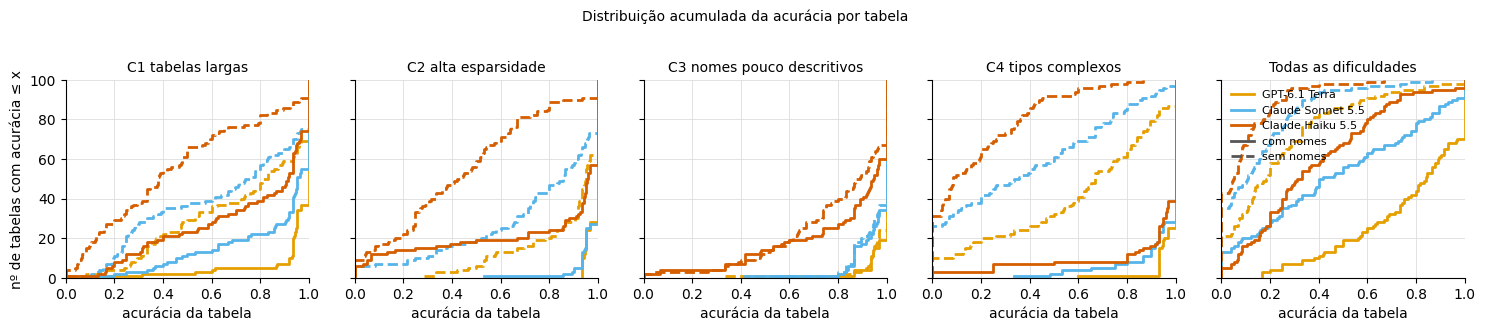

In [15]:
pt = real[real.fase == FULL].groupby(["model", "ver", "hdr", "t"]).ok.mean().rename("acc").reset_index()
dist = pt.groupby(["model", "ver", "hdr"]).acc.agg(mediana="median", **{"tabelas < 50%": lambda s: int((s < 0.5).sum()), "tabelas = 100%": lambda s: int((s == 1).sum())})
dist = dist.reindex(pd.MultiIndex.from_product([MODELS, VERS, HDRS]))
dist.index = pd.MultiIndex.from_tuples([(MODEL_PT[m], VER_PT[v], HDR_PT[h]) for m, v, h in dist.index], names=["Modelo", "Versão", "Condição"])
print("Acurácia por tabela (proporção de colunas anotadas corretas em cada uma das 100 tabelas)")
display(dist)

fig, axes = plt.subplots(1, 5, figsize=(15, 3.2), sharey=True)
for ax, v in zip(axes, VERS):
    for m in MODELS:
        for h, ls in [("with-headers", "-"), ("without-headers", "--")]:
            a = np.sort(pt[(pt.model == m) & (pt.ver == v) & (pt.hdr == h)].acc.values)
            ax.step(a, np.arange(1, len(a) + 1), where="post", color=MODEL_COLOR[m], ls=ls, lw=2)
    ax.set_title(VER_PT[v], fontsize=10); ax.set_xlim(0, 1); ax.set_ylim(0, 100); ax.set_xlabel("acurácia da tabela")
    ax.grid(color="#dddddd", lw=0.6); ax.set_axisbelow(True)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
axes[0].set_ylabel("nº de tabelas com acurácia ≤ x")
for m in MODELS: axes[-1].plot([], [], color=MODEL_COLOR[m], lw=2, label=MODEL_PT[m])
axes[-1].plot([], [], color="#555555", lw=2, ls="-", label="com nomes"); axes[-1].plot([], [], color="#555555", lw=2, ls="--", label="sem nomes")
axes[-1].legend(loc="upper left", frameon=False, fontsize=8)
fig.suptitle("Distribuição acumulada da acurácia por tabela", fontsize=10, y=1.02); fig.tight_layout()
fig.savefig(ROOT / "graficos/analise_acuracia_por_tabela.png", dpi=300, bbox_inches="tight"); fig.savefig(ROOT / "graficos/analise_acuracia_por_tabela.pdf", bbox_inches="tight")
plt.show()

## 12. Modelos atuais: respostas com raciocínio (descritivo, não causal)

In [16]:
x = real[real.fase == FULL].merge(T_full[["model", "ver", "hdr", "t", "raciocinio"]], on=["model", "ver", "hdr", "t"])
ptt = x.groupby(["model", "ver", "hdr", "t", "raciocinio"]).ok.mean().rename("acc").reset_index()
rz = ptt.groupby(["model", "ver", "hdr", "raciocinio"]).acc.agg(["mean", "size"]).unstack("raciocinio")
rz.columns = ["acurácia média s/ raciocínio", "acurácia média c/ raciocínio", "tabelas s/ raciocínio", "tabelas c/ raciocínio"]
rz = rz.reindex(pd.MultiIndex.from_product([MODELS, VERS, HDRS]))
rz[["tabelas s/ raciocínio", "tabelas c/ raciocínio"]] = rz[["tabelas s/ raciocínio", "tabelas c/ raciocínio"]].fillna(0).astype(int)
rz.index = pd.MultiIndex.from_tuples([(MODEL_PT[m], VER_PT[v], HDR_PT[h]) for m, v, h in rz.index], names=["Modelo", "Versão", "Condição"])
display(rz[["tabelas s/ raciocínio", "tabelas c/ raciocínio", "acurácia média s/ raciocínio", "acurácia média c/ raciocínio"]])
print("Respostas com raciocínio (de 500 por célula):")
display(T_full.assign(Modelo=T_full.model.map(MODEL_PT), Condição=T_full.hdr.map(HDR_PT)).groupby(["Modelo", "Condição"]).raciocinio.sum().unstack())

tabelas s/ raciocínio  tabelas c/ raciocínio  acurácia média s/ raciocínio  acurácia média c/ raciocínio
Modelo            Versão                     Condição                                                                                                           
GPT-6.1 Terra     C1 tabelas largas          com nomes                     16                     84                         0.994                         0.944
                                             sem nomes                      4                     96                         0.983                         0.711
                  C2 alta esparsidade        com nomes                     66                     34                         0.990                         0.976
                                             sem nomes                      2                     98                         1.000                         0.876
                  C3 nomes pouco descritivos com nomes                     42                     58                         0.989                         0.984
                                             sem nomes                     17                     83                         1.000                         0.974
                  C4 tipos complexos         com nomes                     44                     56                         0.996                         0.972
                                             sem nomes                      0                    100                           NaN                         0.607
                  Todas as dificuldades      com nomes                      1                     99                         0.800                         0.766
                                             sem nomes                      0                    100                           NaN                         0.239
Claude Sonnet 5.5 C1 tabelas largas          com nomes                     42                     58                         0.952                         0.803
                                             sem nomes                      5                     95                         0.973                         0.632
                  C2 alta esparsidade        com nomes                     92                      8                         0.977                         1.000
                                             sem nomes                     13                     87                         0.672                         0.750
                  C3 nomes pouco descritivos com nomes                     69                     31                         0.956                         0.976
                                             sem nomes                     35                     65                         0.924                         0.978
                  C4 tipos complexos         com nomes                     77                     23                         0.951                         0.955
                                             sem nomes                     11                     89                         0.410                         0.376
                  Todas as dificuldades      com nomes                     25                     75                         0.563                         0.441
                                             sem nomes                      1                     99                         0.000                         0.151
Claude Haiku 5.5  C1 tabelas largas          com nomes                     15                     85                         0.731                         0.753
                                             sem nomes                      2                     98                         0.800                         0.437
                  C2 alta esparsidade        com nomes                     52                     48                         0.650                         0.962
                               

Respostas com raciocínio (de 500 por célula):


Condição,com nomes,sem nomes
Modelo,,
Claude Haiku 5.5,377,487
Claude Sonnet 5.5,195,435
GPT-4o (2024-08-06),0,0
GPT-4o-Mini (2024-07-18),0,0
GPT-6.1 Terra,331,477


## 13. Modelos atuais: colunas numéricas e não numéricas

In [17]:
rows = []
for m, v, h, dt in itertools.product(MODELS, VERS, HDRS, ["numerical", "non-numerical"]):
    g = run(m, v, h, df=real); g = g[g.dtype == dt]
    rows.append({"Modelo": MODEL_PT[m], "Versão": VER_PT[v], "col": f"{HDR_PT[h]} · {'numérica' if dt == 'numerical' else 'não numérica'}", "acc": g.ok.mean(), "n": len(g)})
dtab = pd.DataFrame(rows)
print("Acurácia por tipo de dado da coluna")
display(dtab.pivot(index=["Modelo", "Versão"], columns="col", values="acc").reindex(pd.MultiIndex.from_product([[MODEL_PT[m] for m in MODELS], [VER_PT[v] for v in VERS]])))
print("Colunas avaliadas por tipo de dado (iguais para todos os modelos):")
display(dtab[(dtab.Modelo == MODEL_PT[MODELS[0]]) & dtab.col.str.startswith("com nomes")].pivot(index="Versão", columns="col", values="n").loc[[VER_PT[v] for v in VERS]])

Acurácia por tipo de dado da coluna


col                                           com nomes · numérica  com nomes · não numérica  sem nomes · numérica  sem nomes · não numérica
GPT-6.1 Terra     C1 tabelas largas                          0.958                     0.942                 0.713                     0.835
                  C2 alta esparsidade                        0.991                     0.944                 0.885                     0.866
                  C3 nomes pouco descritivos                 0.990                     0.961                 0.972                     0.969
                  C4 tipos complexos                         0.987                     0.968                 0.658                     0.453
                  Todas as dificuldades                      0.799                     0.826                 0.273                     0.221
Claude Sonnet 5.5 C1 tabelas largas                          0.884                     0.892                 0.629                     0.835
                  C2 alta esparsidade                        0.988                     0.922                 0.773                     0.766
                  C3 nomes pouco descritivos                 0.970                     0.929                 0.972                     0.910
                  C4 tipos complexos                         0.971                     0.854                 0.442                     0.328
                  Todas as dificuldades                      0.492                     0.531                 0.160                     0.147
Claude Haiku 5.5  C1 tabelas largas                          0.773                     0.819                 0.409                     0.677
                  C2 alta esparsidade                        0.808                     0.717                 0.361                     0.606
                  C3 nomes pouco descritivos                 0.829                     0.882                 0.743                     0.902
                  C4 tipos complexos                         0.921                     0.899                 0.202                     0.202
                  Todas as dificuldades                      0.391                     0.527                 0.090                     0.128

Colunas avaliadas por tipo de dado (iguais para todos os modelos):


col,com nomes · numérica,com nomes · não numérica
Versão,,
C1 tabelas largas,1782,260
C2 alta esparsidade,1769,269
C3 nomes pouco descritivos,1775,255
C4 tipos complexos,1745,247
Todas as dificuldades,1707,258


## 14. Piloto de 5 tabelas comparado às 100 tabelas

In [18]:
rows = []
pilot_tables = sorted(tabs[tabs.fase == PILOT].t.unique())
for m in ["gpt-4o-2024-08-06", "gpt-6.1-terra", "claude-sonnet-5-5", "claude-haiku-5-5", "claude-fable-5-2"]:
    for v, h in itertools.product(VERS, HDRS):
        g = run(m, v, h, fase=PILOT)
        row = {"Modelo": MODEL_PT[m], "Versão": VER_PT[v], "Condição": HDR_PT[h], "F1 nas 5 tabelas do piloto": weighted_f1(g.tc, g.pc), "F1 nas 100 tabelas": np.nan}
        if m in MODELS + REPL:
            row["F1 nas 100 tabelas"] = OBS[m, v, h]
        rows.append(row)
pil = pd.DataFrame(rows); pil["diferença"] = pil["F1 nas 5 tabelas do piloto"] - pil["F1 nas 100 tabelas"]
print("tabelas do piloto:", pilot_tables)
d = pil.dropna(subset=["diferença"]).diferença
print(f"Nos {pil.dropna(subset=['diferença']).Modelo.nunique()} modelos com rodada completa ({len(d)} execuções): |F1 do piloto − F1 das 100 tabelas| mediana = {d.abs().median():.3f}, máximo = {d.abs().max():.3f}")
display(pil.pivot(index=["Modelo", "Condição"], columns="Versão", values="F1 nas 5 tabelas do piloto")[[VER_PT[v] for v in VERS]])
display(pil.dropna().set_index(["Modelo", "Versão", "Condição"]).sort_values("diferença", key=abs, ascending=False).head(8))
p4 = tabs[(tabs.fase == PILOT) & (tabs.model == "gpt-4o-2024-08-06")]
print("GPT-4o no piloto: respostas cortadas no limite de saída (finish_reason = length):", int((p4.stop == "length").sum()), "de", len(p4))

tabelas do piloto: [np.int64(0), np.int64(1), np.int64(10), np.int64(11), np.int64(12)]
Nos 4 modelos com rodada completa (40 execuções): |F1 do piloto − F1 das 100 tabelas| mediana = 0.059, máximo = 0.293


Versão                         C1 tabelas largas  C2 alta esparsidade  C3 nomes pouco descritivos  C4 tipos complexos  Todas as dificuldades
Modelo              Condição                                                                                                                
Claude Fable 5.2    com nomes              0.975                0.986                       0.976               0.979                  0.850
                    sem nomes              0.942                0.980                       0.976               0.584                  0.606
Claude Haiku 5.5    com nomes              0.965                0.572                       0.700               0.975                  0.615
                    sem nomes              0.495                0.526                       0.471               0.352                  0.244
Claude Sonnet 5.5   com nomes              0.994                0.979                       0.985               0.984                  0.423
                    sem nomes              0.816                0.784                       0.982               0.338                  0.194
GPT-4o (2024-08-06) com nomes              0.724                0.972                       0.722               0.908                  0.552
                    sem nomes              0.461                0.205                       0.580               0.201                  0.075
GPT-6.1 Terra       com nomes              0.994                0.986                       0.976               0.984                  0.928
                    sem nomes              0.839                0.852                       0.940               0.707                  0.397

F1 nas 5 tabelas do piloto  F1 nas 100 tabelas  diferença
Modelo              Versão                     Condição                                                            
Claude Haiku 5.5    C3 nomes pouco descritivos sem nomes                       0.471               0.765     -0.293
GPT-4o (2024-08-06) C1 tabelas largas          sem nomes                       0.461               0.227      0.235
Claude Haiku 5.5    C2 alta esparsidade        com nomes                       0.572               0.803     -0.231
                    Todas as dificuldades      com nomes                       0.615               0.413      0.202
GPT-4o (2024-08-06) Todas as dificuldades      com nomes                       0.552               0.382      0.169
Claude Haiku 5.5    C1 tabelas largas          com nomes                       0.965               0.814      0.151
Claude Sonnet 5.5   C1 tabelas largas          sem nomes                       0.816               0.670      0.146
                    Todas as dificuldades      com nomes                       0.423               0.569     -0.145

GPT-4o no piloto: respostas cortadas no limite de saída (finish_reason = length): 7 de 50


## 15. Custo e tokens

In [19]:
res = pd.read_csv(ROOT / "logs_replicacao/completa_resumo.csv")      # gerado em 2026-11-15: os três modelos atuais
c = res.groupby("modelo").agg(respostas=("respostas", "sum"), com_raciocinio=("respostas_com_raciocinio", "sum"), tokens_entrada=("tokens_entrada", "sum"),
                              tokens_saida=("tokens_saida", "sum"), custo_calculado_usd=("custo_calculado_usd", "sum"), custo_informado_usd=("custo_informado_api_usd", "sum")).loc[MODELS]
r = T_all[T_all.model.isin(REPL)].groupby("model").agg(respostas=("t", "size"), com_raciocinio=("raciocinio", "sum"), tokens_entrada=("tokens_entrada", "sum"),
                                                        tokens_saida=("tokens_saida", "sum"), custo_informado_usd=("custo_informado", "sum")).loc[REPL]
c = pd.concat([r, c])
c["F1 médio (10 execuções)"] = pd.Series({m: np.mean([OBS[m, v, h] for v in VERS for h in HDRS]) for m in c.index})
c["tokens de saída por resposta"] = c.tokens_saida / c.respostas
c.index = [MODEL_PT[m] for m in c.index]
pd.options.display.float_format = "{:,.2f}".format
display(c)
pd.options.display.float_format = "{:.3f}".format

,respostas,com_raciocinio,tokens_entrada,tokens_saida,custo_informado_usd,custo_calculado_usd,F1 médio (10 execuções),tokens de saída por resposta
GPT-4o (2024-08-06),1000,0,"4,555,712.00",2348842,31.04,NaN,0.47,"2,348.84"
GPT-4o-Mini (2024-07-18),1000,0,"4,555,712.00",1480855,1.32,NaN,0.21,"1,480.86"
GPT-6.1 Terra,1000,808,"4,556,712.00",647641,8.93,7.79,0.83,647.64
Claude Sonnet 5.5,1000,630,"7,039,155.00",1451622,0.00,28.59,0.74,"1,451.62"
Claude Haiku 5.5,1000,864,"7,039,155.00",2634178,0.00,2.02,0.58,"2,634.18"


Para reexecutar: `jupyter nbconvert --to notebook --execute --inplace analise_resultados.ipynb` na raiz do repositório, com o venv ativado. Figuras em `graficos/analise_*`.